In [2]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install datasets

  Using cached datasets-5.2.0-py3-none-any.whl.metadata (24 kB)
  Using cached dill-0.4.1-py3-none-any.whl.metadata (10 kB)
  Using cached multiprocess-0.70.19-py312-none-any.whl.metadata (7.5 kB)
  Using cached huggingface_hub-2.4.0-py3-none-any.whl.metadata (16 kB)
  Using cached hf_xet-1.8.0-cp38-abi3-macosx_10_12_x86_64.whl.metadata (4.9 kB)
  Using cached httpx2-2.16.2-py3-none-any.whl.metadata (10.0 kB)
  Using cached httpcore2-2.16.2-py3-none-any.whl.metadata (28 kB)
  Using cached truststore-0.10.5-py3-none-any.whl.metadata (4.5 kB)
Using cached datasets-5.2.0-py3-none-any.whl (608 kB)
Using cached dill-0.4.1-py3-none-any.whl (120 kB)
Using cached huggingface_hub-2.4.0-py3-none-any.whl (857 kB)
Using cached hf_xet-1.8.0-cp38-abi3-macosx_10_12_x86_64.whl (3.9 MB)
Using cached httpx2-2.16.2-py3-none-any.whl (97 kB)
Using cached httpcore2-2.16.2-py3-none-any.whl (85 kB)
Using cached multiprocess-0.70.19-py312-none-any.whl (150 kB)
Using cached truststore-0.10.5-py3-none-any.whl (1

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import pandas as pd

# URL of the Inspec training dataset
url = "https://huggingface.co/datasets/taln-ls2n/inspec/resolve/main/train.jsonl"

# Load JSONL file directly
df = pd.read_json(url, lines=True)

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [4]:
df.head()

,id,title,abstract,tok_text,ordered_present_kp,keyphrases,prmu
0,761,Towards a NMR implementation of a quantum latt...,Recent theoretical results suggest that an arr...,toward a nmr implement of a quantum lattic ga ...,"[9, 28, 105, 176, 288, 309, 388]","[NMR implementation, quantum lattice gas algor...","[P, P, P, P, P, P, P, M]"
1,724,Banking on SMA funds [separately managed accou...,From investment management to technology to ba...,bank on sma fund [ separ manag account ] \n fr...,"[19, 48, 64, 77, 97, 146]","[separately managed accounts, investment manag...","[P, P, P, P, P, P]"
2,1371,Design methodology for diagnostic strategies f...,This paper presents a method for the construct...,design methodolog for diagnost strategi for in...,"[0, 259, 451, 22, 44]","[design methodology, diagnostic strategies, in...","[P, P, P, P, P]"
3,1334,A shy invariant of graphs,Moving from a well known result of P.L. Hammer...,a shi invari of graph \n move from a well know...,"[106, 228, 277, 409, 617, 629]","[graph invariant, induced odd cycles, minimum ...","[P, P, P, P, P, P]"
4,1419,PacketVideo. One step ahead of the streaming w...,"Go beyond the hype, however, and it's clear th...",packetvideo . one step ahead of the stream wir...,"[0, 176, 285, 680, 712, 731, 802]","[PacketVideo, wireless devices, MPEG-4, wirele...","[P, P, P, P, P, P, P, R]"


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (1000, 7)

Column Names:
['id', 'title', 'abstract', 'tok_text', 'ordered_present_kp', 'keyphrases', 'prmu']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   id                  1000 non-null   int64 
 1   title               1000 non-null   object
 2   abstract            1000 non-null   object
 3   tok_text            1000 non-null   object
 4   ordered_present_kp  1000 non-null   object
 5   keyphrases          1000 non-null   object
 6   prmu                1000 non-null   object
dtypes: int64(1), object(6)
memory usage: 54.8+ KB


In [6]:
df.to_csv("research_papers.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [7]:
import pandas as pd

df = pd.read_csv("research_papers.csv")

print("Dataset loaded successfully!")
print("Original Shape:", df.shape)

Dataset loaded successfully!
Original Shape: (1000, 7)


In [8]:
# Check missing values in each column
print(df.isnull().sum())

id                    0
title                 0
abstract              0
tok_text              0
ordered_present_kp    0
keyphrases            0
prmu                  0
dtype: int64


In [9]:
 # Remove rows with missing important information
df = df.dropna(subset=['title', 'abstract', 'keyphrases'])

print("Shape after removing missing values:", df.shape)

Shape after removing missing values: (1000, 7)


In [10]:
# Remove duplicate research papers based on abstract
df = df.drop_duplicates(subset=['abstract'])

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (1000, 7)


In [11]:
 # Remove empty or whitespace-only records
df = df[
    (df['title'].astype(str).str.strip() != '') &
    (df['abstract'].astype(str).str.strip() != '')
]

print("Shape after removing empty records:", df.shape)

Shape after removing empty records: (1000, 7)


In [12]:
# Remove extra spaces
df['title'] = df['title'].astype(str).str.strip()
df['abstract'] = df['abstract'].astype(str).str.strip()

print("Text formatting cleaned successfully!")

Text formatting cleaned successfully!


In [13]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated(subset=['abstract']).sum())

df.head()

Final Dataset Shape: (1000, 7)

Missing Values:
id                    0
title                 0
abstract              0
tok_text              0
ordered_present_kp    0
keyphrases            0
prmu                  0
dtype: int64

Duplicate Records:
0


,id,title,abstract,tok_text,ordered_present_kp,keyphrases,prmu
0,761,Towards a NMR implementation of a quantum latt...,Recent theoretical results suggest that an arr...,toward a nmr implement of a quantum lattic ga ...,"[9, 28, 105, 176, 288, 309, 388]","['NMR implementation', 'quantum lattice gas al...","['P', 'P', 'P', 'P', 'P', 'P', 'P', 'M']"
1,724,Banking on SMA funds [separately managed accou...,From investment management to technology to ba...,bank on sma fund [ separ manag account ] \n fr...,"[19, 48, 64, 77, 97, 146]","['separately managed accounts', 'investment ma...","['P', 'P', 'P', 'P', 'P', 'P']"
2,1371,Design methodology for diagnostic strategies f...,This paper presents a method for the construct...,design methodolog for diagnost strategi for in...,"[0, 259, 451, 22, 44]","['design methodology', 'diagnostic strategies'...","['P', 'P', 'P', 'P', 'P']"
3,1334,A shy invariant of graphs,Moving from a well known result of P.L. Hammer...,a shi invari of graph \n move from a well know...,"[106, 228, 277, 409, 617, 629]","['graph invariant', 'induced odd cycles', 'min...","['P', 'P', 'P', 'P', 'P', 'P']"
4,1419,PacketVideo. One step ahead of the streaming w...,"Go beyond the hype, however, and it's clear th...",packetvideo . one step ahead of the stream wir...,"[0, 176, 285, 680, 712, 731, 802]","['PacketVideo', 'wireless devices', 'MPEG-4', ...","['P', 'P', 'P', 'P', 'P', 'P', 'P', 'R']"


In [14]:
df.to_csv("cleaned_research_papers.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [15]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("Libraries and NLTK data loaded successfully!")

[nltk_data] Downloading package stopwords to /Users/apple/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/apple/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /Users/apple/nltk_data...


Libraries and NLTK data loaded successfully!


In [16]:
stop_words = set(stopwords.words('english'))

lemmatizer = WordNetLemmatizer()

print("Stopwords and lemmatizer initialized!")

Stopwords and lemmatizer initialized!


In [17]:
def preprocess_text(text):

    # Convert text into lowercase
    text = str(text).lower()

    # Remove punctuation and numbers, keeping English letters
    words = re.findall(r'\b[a-zA-Z]+\b', text)

    # Remove stopwords
    words = [word for word in words if word not in stop_words]

    # Apply lemmatization
    words = [lemmatizer.lemmatize(word) for word in words]

    # Join words back into a sentence
    return " ".join(words)

In [18]:
df['processed_abstract'] = df['abstract'].apply(preprocess_text)

print("Text preprocessing completed successfully!")

Text preprocessing completed successfully!


In [19]:
df[['abstract', 'processed_abstract']].head()

,abstract,processed_abstract
0,Recent theoretical results suggest that an arr...,recent theoretical result suggest array quantu...
1,From investment management to technology to ba...,investment management technology back office s...
2,This paper presents a method for the construct...,paper present method construction diagnostic s...
3,Moving from a well known result of P.L. Hammer...,moving well known result p l hammer et al intr...
4,"Go beyond the hype, however, and it's clear th...",go beyond hype however clear packetvideo makin...


In [20]:
df.to_csv("preprocessed_research_papers.csv", index=False)

print("Preprocessed dataset saved successfully!")

Preprocessed dataset saved successfully!


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


In [22]:
print("Total Research Papers:", len(df))
print("Total Columns:", len(df.columns))

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe(include='all')

Total Research Papers: 1000
Total Columns: 8

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   id                  1000 non-null   int64 
 1   title               1000 non-null   object
 2   abstract            1000 non-null   object
 3   tok_text            1000 non-null   object
 4   ordered_present_kp  1000 non-null   object
 5   keyphrases          1000 non-null   object
 6   prmu                1000 non-null   object
 7   processed_abstract  1000 non-null   object
dtypes: int64(1), object(7)
memory usage: 62.6+ KB

Statistical Summary:


,id,title,abstract,tok_text,ordered_present_kp,keyphrases,prmu,processed_abstract
count,1000.000000,1000,1000,1000,1000,1000,1000,1000
unique,NaN,1000,1000,1000,995,1000,456,1000
top,NaN,BT voices its support for IP,"BTexact's chief technology officer, Mick Reeve...",bt voic it support for ip \n btexact 's chief ...,[],"['BTexact', 'voice over DSL', 'virtual private...","['P', 'P', 'P', 'P', 'P']",btexact chief technology officer mick reeve gi...
freq,NaN,1,1,1,3,1,29,1
mean,910.155000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,368.867524,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,6.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,697.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,950.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1201.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
df['abstract_length'] = df['abstract'].apply(
    lambda text: len(str(text).split())
)

print(df[['abstract', 'abstract_length']].head())
print("\nAverage Abstract Length:", df['abstract_length'].mean())
print("Maximum Abstract Length:", df['abstract_length'].max())
print("Minimum Abstract Length:", df['abstract_length'].min())

                                            abstract  abstract_length
0  Recent theoretical results suggest that an arr...              136
1  From investment management to technology to ba...               27
2  This paper presents a method for the construct...               73
3  Moving from a well known result of P.L. Hammer...              119
4  Go beyond the hype, however, and it's clear th...              121

Average Abstract Length: 118.935
Maximum Abstract Length: 477
Minimum Abstract Length: 10


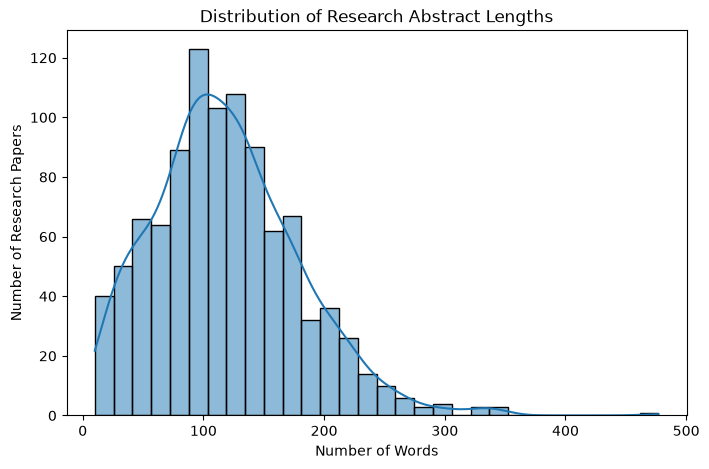

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(df['abstract_length'], bins=30, kde=True)

plt.title("Distribution of Research Abstract Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Research Papers")

plt.show()

In [25]:
all_words = " ".join(df['processed_abstract']).split()

word_counts = Counter(all_words)

most_common_words = word_counts.most_common(15)

words = [item[0] for item in most_common_words]
counts = [item[1] for item in most_common_words]

print("15 Most Frequent Words:")
print(most_common_words)

15 Most Frequent Words:
[('system', 766), ('method', 488), ('model', 423), ('paper', 403), ('based', 388), ('using', 350), ('time', 348), ('problem', 340), ('algorithm', 339), ('control', 339), ('data', 317), ('result', 316), ('information', 286), ('two', 276), ('new', 267)]


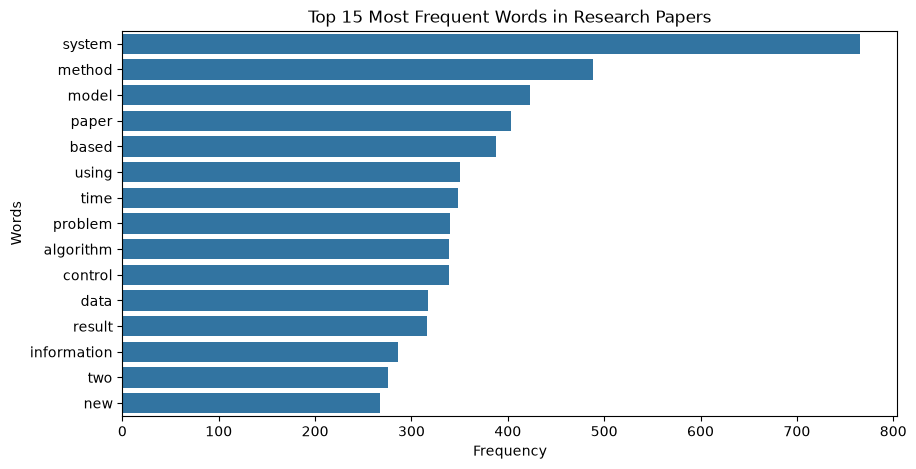

In [26]:
plt.figure(figsize=(10, 5))

sns.barplot(x=counts, y=words)

plt.title("Top 15 Most Frequent Words in Research Papers")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.show()

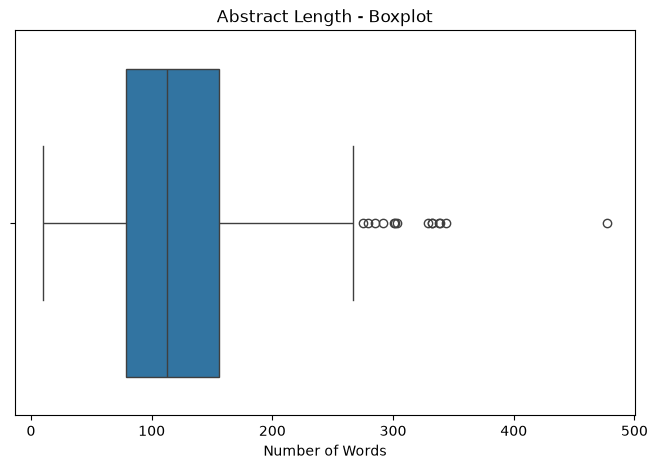

In [27]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df['abstract_length'])

plt.title("Abstract Length - Boxplot")
plt.xlabel("Number of Words")

plt.show()

In [28]:
df.to_csv("eda_research_papers.csv", index=False)

print("EDA dataset saved successfully!")

EDA dataset saved successfully!


In [29]:
from sklearn.feature_extraction.text import CountVectorizer

print("CountVectorizer imported successfully!")

CountVectorizer imported successfully!


In [30]:
bow_vectorizer = CountVectorizer(max_features=1000)

bow_matrix = bow_vectorizer.fit_transform(df['processed_abstract'])

print("Bag of Words created successfully!")
print("Matrix Shape:", bow_matrix.shape)

Bag of Words created successfully!
Matrix Shape: (1000, 1000)


In [31]:
bow_features = bow_vectorizer.get_feature_names_out()

print("First 20 Words:")
print(bow_features[:20])

First 20 Words:
['ability' 'able' 'academic' 'access' 'according' 'account' 'accuracy'
 'accurate' 'achieve' 'achieved' 'acquisition' 'across' 'action' 'active'
 'activity' 'actuator' 'adaptive' 'add' 'addition' 'additional']


In [32]:
bow_df = pd.DataFrame(
    bow_matrix[:5].toarray(),
    columns=bow_features
)

bow_df.iloc[:, :15]

,ability,able,academic,access,according,account,accuracy,accurate,achieve,achieved,acquisition,across,action,active,activity
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [33]:
from sklearn.feature_extraction.text import TfidfVectorizer

print("TfidfVectorizer imported successfully!")

TfidfVectorizer imported successfully!


In [34]:
tfidf_vectorizer = TfidfVectorizer(max_features=1000)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    df['processed_abstract']
)

print("TF-IDF created successfully!")
print("Matrix Shape:", tfidf_matrix.shape)

TF-IDF created successfully!
Matrix Shape: (1000, 1000)


In [35]:
tfidf_features = tfidf_vectorizer.get_feature_names_out()

print("First 20 TF-IDF Features:")
print(tfidf_features[:20])

First 20 TF-IDF Features:
['ability' 'able' 'academic' 'access' 'according' 'account' 'accuracy'
 'accurate' 'achieve' 'achieved' 'acquisition' 'across' 'action' 'active'
 'activity' 'actuator' 'adaptive' 'add' 'addition' 'additional']


In [36]:
tfidf_df = pd.DataFrame(
    tfidf_matrix[:5].toarray(),
    columns=tfidf_features
)

tfidf_df.iloc[:, :15]

,ability,able,academic,access,according,account,accuracy,accurate,achieve,achieved,acquisition,across,action,active,activity
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [37]:
print("Bag of Words Matrix Shape:", bow_matrix.shape)
print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

print("\nBoW and TF-IDF comparison completed!")

Bag of Words Matrix Shape: (1000, 1000)
TF-IDF Matrix Shape: (1000, 1000)

BoW and TF-IDF comparison completed!


In [38]:
bow_df.to_csv("bow_features.csv", index=False)
tfidf_df.to_csv("tfidf_features.csv", index=False)

print("Feature files saved successfully!")

Feature files saved successfully!


In [39]:
def extract_tfidf_keywords(text, top_n=10):

    # Convert the text into TF-IDF values
    text_vector = tfidf_vectorizer.transform([text])

    # Get the TF-IDF scores
    scores = text_vector.toarray()[0]

    # Get word indices sorted by highest score
    top_indices = scores.argsort()[::-1][:top_n]

    # Extract words and their scores
    keywords = []

    for index in top_indices:
        if scores[index] > 0:
            word = tfidf_features[index]
            score = scores[index]
            keywords.append((word, round(score, 4)))

    return keywords

In [40]:
sample_text = df['processed_abstract'].iloc[0]

tfidf_keywords = extract_tfidf_keywords(sample_text, top_n=10)

print("TF-IDF Extracted Keywords:")
for word, score in tfidf_keywords:
    print(word, ":", score)

TF-IDF Extracted Keywords:
quantum : 0.3366
equation : 0.2943
implementation : 0.2896
mass : 0.2667
processor : 0.2637
density : 0.2608
solve : 0.2486
result : 0.1848
technique : 0.1627
information : 0.1526


In [41]:
%pip install rake-nltk


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [42]:
from rake_nltk import Rake

rake_extractor = Rake()

print("RAKE initialized successfully!")

RAKE initialized successfully!


In [43]:
def extract_rake_keywords(text, top_n=10):

    rake_extractor.extract_keywords_from_text(str(text))

    keywords = rake_extractor.get_ranked_phrases_with_scores()

    return keywords[:top_n]

In [44]:
sample_text = df['abstract'].iloc[0]

rake_keywords = extract_rake_keywords(sample_text, top_n=10)

print("RAKE Extracted Keywords:")

for score, phrase in rake_keywords:
    print(phrase, ":", round(score, 2))

RAKE Extracted Keywords:
quantum information processors communicating via classical channels : 43.33
qubit quantum information processors : 19.33
using standard pulse techniques : 15.0
recent theoretical results suggest : 15.0
solve fluid dynamics problems : 14.5
ensemble nuclear magnetic resonance : 14.5
observed implementation errors highlight : 14.33
results qualitatively follow : 9.0
nonlinear burgers equations : 9.0
describe progress towards : 9.0


In [45]:
print("TF-IDF Keywords:\n")

for word, score in tfidf_keywords:
    print(word, ":", score)


print("\nRAKE Keywords:\n")

for score, phrase in rake_keywords:
    print(phrase, ":", round(score, 2))

TF-IDF Keywords:

quantum : 0.3366
equation : 0.2943
implementation : 0.2896
mass : 0.2667
processor : 0.2637
density : 0.2608
solve : 0.2486
result : 0.1848
technique : 0.1627
information : 0.1526

RAKE Keywords:

quantum information processors communicating via classical channels : 43.33
qubit quantum information processors : 19.33
using standard pulse techniques : 15.0
recent theoretical results suggest : 15.0
solve fluid dynamics problems : 14.5
ensemble nuclear magnetic resonance : 14.5
observed implementation errors highlight : 14.33
results qualitatively follow : 9.0
nonlinear burgers equations : 9.0
describe progress towards : 9.0


In [46]:
df['tfidf_keywords'] = df['processed_abstract'].apply(
    lambda text: extract_tfidf_keywords(text, top_n=10)
)

df['rake_keywords'] = df['abstract'].apply(
    lambda text: extract_rake_keywords(text, top_n=10)
)

print("Keywords extracted for all research papers!")

Keywords extracted for all research papers!


In [47]:
df[['title', 'tfidf_keywords', 'rake_keywords']].head()

,title,tfidf_keywords,rake_keywords
0,Towards a NMR implementation of a quantum latt...,"[(quantum, 0.3366), (equation, 0.2943), (imple...","[(43.33333333333333, quantum information proce..."
1,Banking on SMA funds [separately managed accou...,"[(sma, 0.425), (investment, 0.3895), (bank, 0....","[(4.0, small banks), (4.0, sma business), (4.0..."
2,Design methodology for diagnostic strategies f...,"[(developed, 0.31), (different, 0.2874), (cycl...","[(16.0, consider multiple simultaneous failure..."
3,A shy invariant of graphs,"[(minimum, 0.4346), (graph, 0.4273), (non, 0.2...","[(55.31818181818181, zero whenever g contains ..."
4,PacketVideo. One step ahead of the streaming w...,"[(wireless, 0.5035), (company, 0.3652), (conte...","[(33.5, standard motion pictures expert group ..."


In [48]:
df.to_csv("keyword_extraction_results.csv", index=False)

print("Keyword extraction results saved successfully!")

Keyword extraction results saved successfully!


In [49]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /Users/apple/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [50]:
import ast
import re
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

print("Evaluation libraries imported successfully!")

Evaluation libraries imported successfully!


In [51]:
def parse_keyphrases(value):

    if isinstance(value, list):
        return value

    try:
        result = ast.literal_eval(str(value))

        if isinstance(result, list):
            return result

    except (ValueError, SyntaxError):
        pass

    return [str(value)]


df['actual_keywords'] = df['keyphrases'].apply(parse_keyphrases)

print(df[['actual_keywords']].head())

                                     actual_keywords
0  [NMR implementation, quantum lattice gas algor...
1  [separately managed accounts, investment manag...
2  [design methodology, diagnostic strategies, in...
3  [graph invariant, induced odd cycles, minimum ...
4  [PacketVideo, wireless devices, MPEG-4, wirele...


In [52]:
def normalize_text(text):
    text = str(text).lower()
    words = re.findall(r'[a-z]+', text)
    return " ".join(words)


def get_reference_words(keyphrases):
    words = set()

    for phrase in keyphrases:
        words.update(normalize_text(phrase).split())

    return words


def get_reference_phrases(keyphrases):
    return {
        normalize_text(phrase)
        for phrase in keyphrases
        if normalize_text(phrase)
    }

In [53]:
tfidf_precision = []
tfidf_recall = []
tfidf_f1 = []

for _, row in df.iterrows():

    actual = get_reference_words(row['actual_keywords'])

    predicted = {
        normalize_text(word)
        for word, score in row['tfidf_keywords']
    }

    predicted = predicted - {''}

    common = actual.intersection(predicted)

    precision = len(common) / len(predicted) if predicted else 0
    recall = len(common) / len(actual) if actual else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    tfidf_precision.append(precision)
    tfidf_recall.append(recall)
    tfidf_f1.append(f1)


print("TF-IDF Evaluation Completed!")

TF-IDF Evaluation Completed!


In [54]:
rake_precision = []
rake_recall = []
rake_f1 = []

for _, row in df.iterrows():

    actual = get_reference_phrases(row['actual_keywords'])

    predicted = {
        normalize_text(phrase)
        for score, phrase in row['rake_keywords']
    }

    predicted = predicted - {''}

    common = actual.intersection(predicted)

    precision = len(common) / len(predicted) if predicted else 0
    recall = len(common) / len(actual) if actual else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    rake_precision.append(precision)
    rake_recall.append(recall)
    rake_f1.append(f1)


print("RAKE Evaluation Completed!")

RAKE Evaluation Completed!


In [55]:
evaluation_results = pd.DataFrame({
    'Model': ['TF-IDF', 'RAKE'],

    'Precision': [
        np.mean(tfidf_precision),
        np.mean(rake_precision)
    ],

    'Recall': [
        np.mean(tfidf_recall),
        np.mean(rake_recall)
    ],

    'F1-Score': [
        np.mean(tfidf_f1),
        np.mean(rake_f1)
    ]
})

print("Model Evaluation Results:")
display(evaluation_results.round(4))

Model Evaluation Results:


,Model,Precision,Recall,F1-Score
0,TF-IDF,0.4256,0.2266,0.2795
1,RAKE,0.1739,0.1924,0.1728


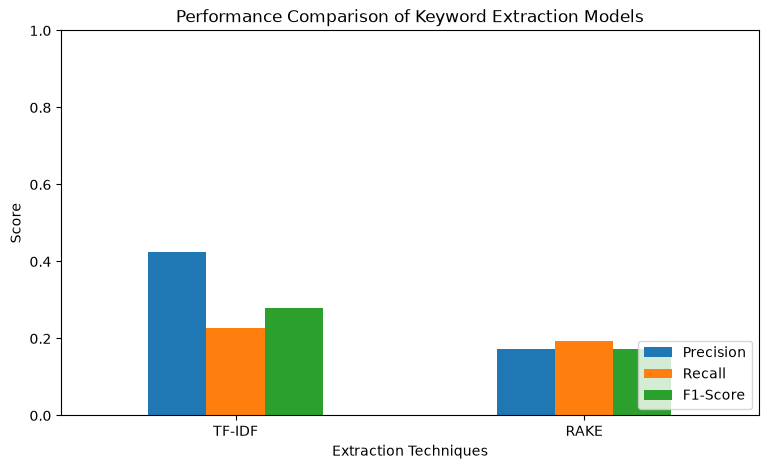

In [56]:
evaluation_results.set_index('Model').plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Performance Comparison of Keyword Extraction Models")
plt.xlabel("Extraction Techniques")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

In [57]:
evaluation_results.to_csv(
    "model_evaluation_results.csv",
    index=False
)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [58]:
import joblib

joblib.dump(tfidf_vectorizer, "tfidf_vectorizer.pkl")

print("TF-IDF vectorizer saved successfully!")

TF-IDF vectorizer saved successfully!


In [59]:
%pip install streamlit joblib rake-nltk


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
